Loading datasets...
Area fraction of each combination (0-200 m):
                             all cells   robust cells
N2 ↑, DICsoft ↑                  51.3%          62.5%
N2 ↑, DICsoft ↓                  30.0%          17.7%
N2 ↓, DICsoft ↑                  13.7%          16.3%
N2 ↓, DICsoft ↓                   4.9%           3.5%
Figure saved to: figs/FigureSX_N2_DICsoft_sign_agreement.png


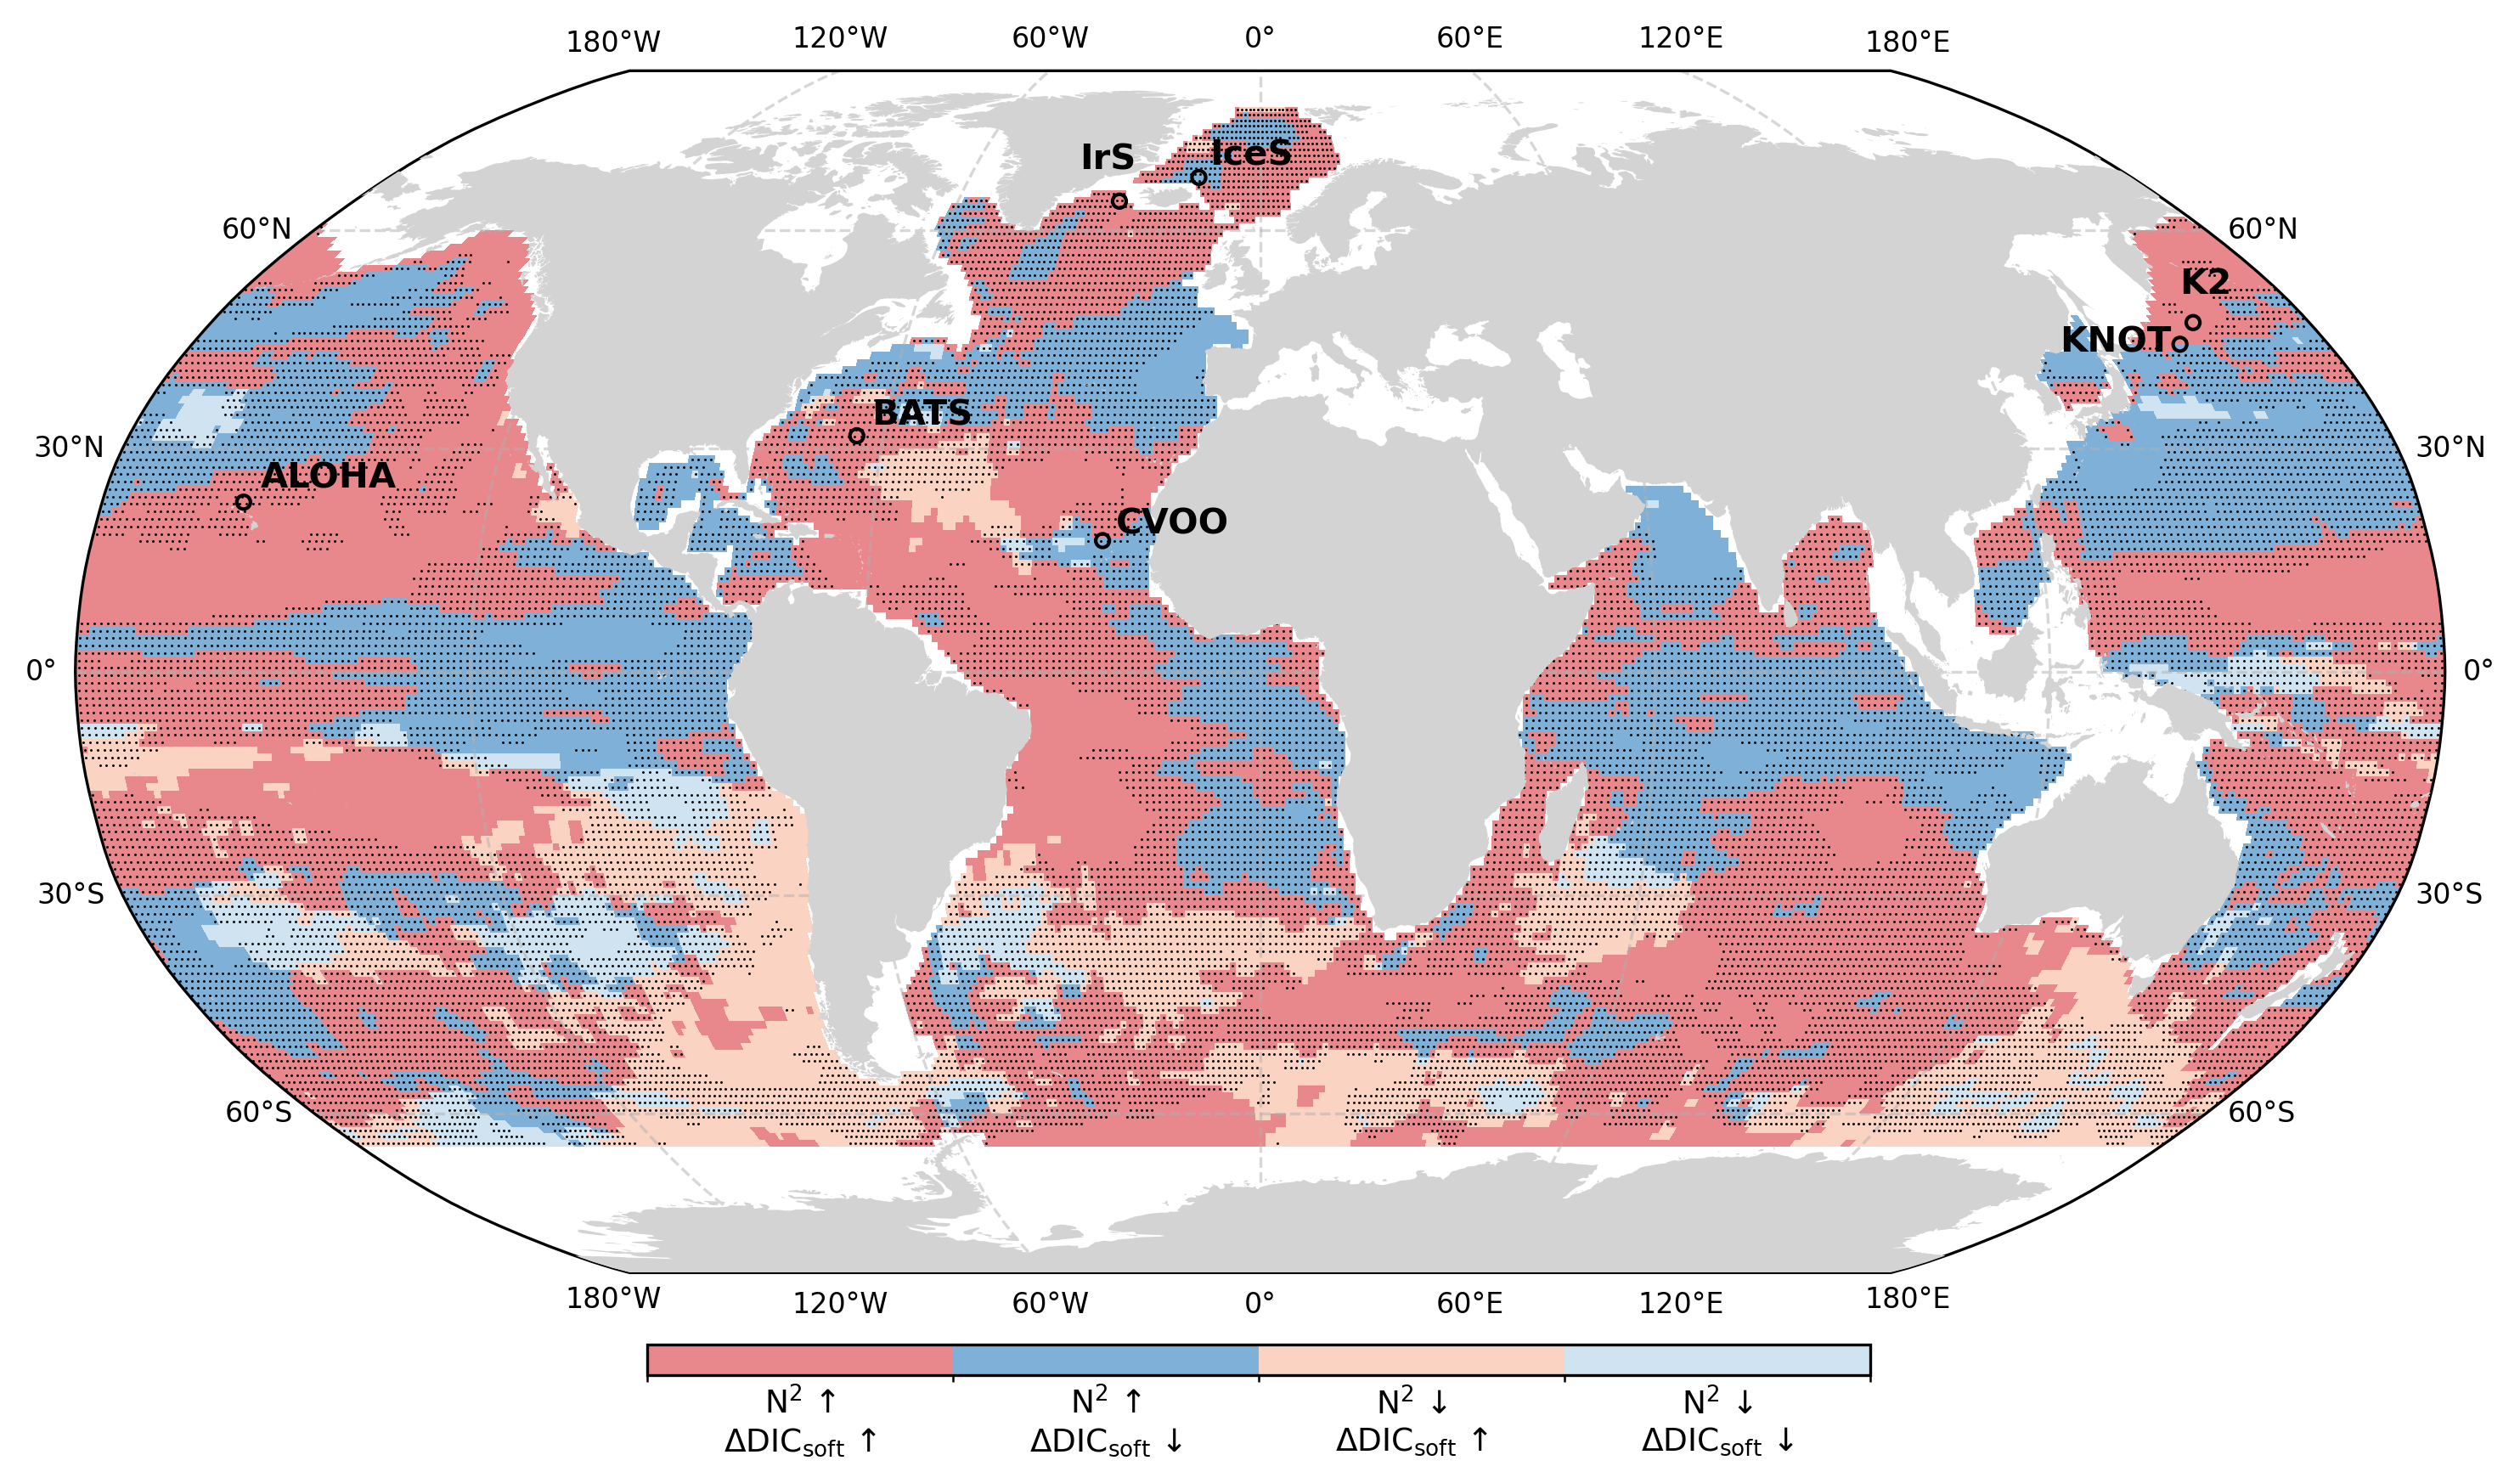

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Polygon
import xarray as xr
import matplotlib.ticker as mticker
import cartopy.mpl.ticker as cticker

# -------------------------------------------------------------------
# USER SETTINGS
# -------------------------------------------------------------------
ZERO_TREND_TOL = 1e-12

# Monte Carlo robustness threshold (same as Fig. 3):
# a pixel is considered robust only if >= 80% of iterations are
# significant and have the same sign
ROBUSTNESS_THRESHOLD = 0.80
NUM_ITERATIONS = 1000

# Stipple appearance
STIPPLE_SIZE = 2.0
STIPPLE_COLOR = "black"

# Categories (sign of N2 trend, sign of DICsoft trend)
CATEGORY_LABELS = {
    1: "N$^2$ ↑\nΔDIC$_{\\mathrm{soft}}$ ↑",
    2: "N$^2$ ↑\nΔDIC$_{\\mathrm{soft}}$ ↓",
    3: "N$^2$ ↓\nΔDIC$_{\\mathrm{soft}}$ ↑",
    4: "N$^2$ ↓\nΔDIC$_{\\mathrm{soft}}$ ↓",
}
CATEGORY_COLORS = ["#e8888c", "#7fb1d8", "#fbd3c2", "#cfe3f1"]  # lightened so stippling stays visible

# Mediterranean white rectangle in PlateCarree coordinates
MED_POLYGON = [
    (-6.5, 35.0),
    (-6.5, 36.8),
    (-4.5, 37.4),
    (-2.0, 39.0),
    (1.5, 42.3),
    (5.5, 44.5),
    (9.5, 45.8),
    (14.5, 46.5),
    (19.5, 46.2),
    (24.0, 45.0),
    (28.5, 42.8),
    (33.0, 39.0),
    (36.8, 35.2),
    (36.8, 30.0),
    (33.0, 29.6),
    (28.0, 29.6),
    (22.0, 29.8),
    (16.0, 30.0),
    (10.0, 30.0),
    (4.0, 30.0),
    (-1.0, 30.8),
    (-5.0, 33.0),
    (-6.5, 35.0),
]

# -------------------------------------------------------------------
# Paths
# -------------------------------------------------------------------
dic_path = "data/processing_steps/07A_DIC_band_0_200_monte_carlo.nc"
n2_path = "data/processing_steps/06_N2_stratification_trend.nc"
output_figure = "figs/FigureSX_N2_DICsoft_sign_agreement.png"

# -------------------------------------------------------------------
# Load datasets and align grids
# -------------------------------------------------------------------
print("Loading datasets...")
dic_ds = xr.load_dataset(dic_path)
n2_da = xr.load_dataset(n2_path)["trend_N2bar_0_200_peryr"]

dic_ds, n2_da = xr.align(dic_ds, n2_da, join="inner")

# -------------------------------------------------------------------
# Extract coordinates
# -------------------------------------------------------------------
lon = dic_ds.coords["lon"].values
lat = dic_ds.coords["lat"].values

# Convert longitudes to [-180, 180]
lon_wrapped = ((lon + 180) % 360) - 180

# Sort by longitude so plotting is continuous
sort_idx = np.argsort(lon_wrapped)
lon_wrapped = lon_wrapped[sort_idx]

# -------------------------------------------------------------------
# Extract variables and reorder longitude dimension
# -------------------------------------------------------------------
dic_data = dic_ds["soft_pump_aou_change"].transpose("lat", "lon").values[:, sort_idx]
uncertainty_data = dic_ds["soft_pump_aou_change_uncertainty"].transpose("lat", "lon").values[:, sort_idx]
sig_pos_count_data = dic_ds["soft_pump_aou_change_significant_positive_count"].transpose("lat", "lon").values[:, sort_idx]
sig_neg_count_data = dic_ds["soft_pump_aou_change_significant_negative_count"].transpose("lat", "lon").values[:, sort_idx]
n2_data = n2_da.transpose("lat", "lon").values[:, sort_idx]

# Build 2D coordinates after sorting
lon_2d, lat_2d = np.meshgrid(lon_wrapped, lat)

# -------------------------------------------------------------------
# Build masks for valid ocean plotting
# -------------------------------------------------------------------
finite_mask = (
    np.isfinite(dic_data)
    & np.isfinite(uncertainty_data)
    & np.isfinite(sig_pos_count_data)
    & np.isfinite(sig_neg_count_data)
    & np.isfinite(n2_data)
)

nonzero_trend_mask = np.abs(dic_data) > ZERO_TREND_TOL

ocean_valid_mask = finite_mask & (
    (np.abs(dic_data) > ZERO_TREND_TOL) |
    (np.abs(uncertainty_data) > ZERO_TREND_TOL)
)

# -------------------------------------------------------------------
# Monte Carlo robustness using 80% rule (on DICsoft)
# -------------------------------------------------------------------
robust_positive_mask = (sig_pos_count_data / NUM_ITERATIONS) >= ROBUSTNESS_THRESHOLD
robust_negative_mask = (sig_neg_count_data / NUM_ITERATIONS) >= ROBUSTNESS_THRESHOLD
significant_mask = (robust_positive_mask | robust_negative_mask) & ocean_valid_mask
nonsignificant_mask = (~significant_mask) & ocean_valid_mask

# -------------------------------------------------------------------
# Sign-combination categories
# -------------------------------------------------------------------
category = np.full(dic_data.shape, np.nan)
category[ocean_valid_mask & (n2_data > 0) & (dic_data > 0)] = 1
category[ocean_valid_mask & (n2_data > 0) & (dic_data < 0)] = 2
category[ocean_valid_mask & (n2_data < 0) & (dic_data > 0)] = 3
category[ocean_valid_mask & (n2_data < 0) & (dic_data < 0)] = 4

# -------------------------------------------------------------------
# Area fractions (cos(lat) weighting)
# -------------------------------------------------------------------
area_weights = np.cos(np.deg2rad(lat_2d))

def area_fractions(mask):
    valid = mask & np.isfinite(category)
    total = area_weights[valid].sum()
    return {k: 100 * area_weights[valid & (category == k)].sum() / total for k in CATEGORY_LABELS}

frac_all = area_fractions(ocean_valid_mask)
frac_rob = area_fractions(significant_mask)

print("Area fraction of each combination (0-200 m):")
print(f"{'':<26}{'all cells':>12}{'robust cells':>15}")
for k, lab in CATEGORY_LABELS.items():
    name = lab.replace("\n", ", ").replace("$^2$", "2").replace("ΔDIC$_{\\mathrm{soft}}$", "DICsoft")
    print(f"{name:<26}{frac_all[k]:>11.1f}%{frac_rob[k]:>14.1f}%")

# -------------------------------------------------------------------
# Build stippling mask
# Stipple pixels that fail the 80% significant-same-sign criterion
# -------------------------------------------------------------------
stippling_mask = (
    nonsignificant_mask
    & ocean_valid_mask
    & nonzero_trend_mask
)

stipple_lons = lon_2d[stippling_mask]
stipple_lats = lat_2d[stippling_mask]

# -------------------------------------------------------------------
# Create figure
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 8), dpi=300)
ax1 = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax1.set_global()

# -------------------------------------------------------------------
# Gridlines with formatting
# -------------------------------------------------------------------
gl = ax1.gridlines(draw_labels=True, alpha=0.5, linestyle="--")
gl.top_labels = True
gl.bottom_labels = True
gl.right_labels = True
gl.left_labels = True

gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 30))

class CustomLongitudeFormatter(cticker.LongitudeFormatter):
    def __call__(self, lon, pos=None):
        if lon == 0:
            return "0°"
        elif lon < 0:
            return f"{abs(lon):g}°W"
        else:
            return f"{lon:g}°E"

gl.xformatter = CustomLongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for label in gl.xlabel_artists + gl.ylabel_artists:
    label.set_fontsize(8)

# -------------------------------------------------------------------
# Plot sign combinations
# -------------------------------------------------------------------
cmap = ListedColormap(CATEGORY_COLORS)
norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], cmap.N)

im1 = ax1.pcolormesh(
    lon_2d,
    lat_2d,
    category,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    norm=norm,
    shading="auto",
    zorder=1,
)

# -------------------------------------------------------------------
# White rectangle over Mediterranean
# -------------------------------------------------------------------
med_poly = Polygon(
    MED_POLYGON,
    closed=True,
    facecolor="white",
    edgecolor="none",
    transform=ccrs.PlateCarree(),
    zorder=3,
)
ax1.add_patch(med_poly)

# -------------------------------------------------------------------
# Stipple pixels that are NOT robust under the 80% MC rule
# -------------------------------------------------------------------
ax1.scatter(
    stipple_lons,
    stipple_lats,
    s=STIPPLE_SIZE,
    c=STIPPLE_COLOR,
    marker=".",
    linewidths=0,
    alpha=1.0,
    transform=ccrs.PlateCarree(),
    zorder=2,
)

# -------------------------------------------------------------------
# Add land on top of rectangle/data
# -------------------------------------------------------------------
land_feature = cfeature.NaturalEarthFeature(
    "physical",
    "land",
    "50m",
    edgecolor="none",
    facecolor="lightgrey",
)
ax1.add_feature(land_feature, zorder=4)

# -------------------------------------------------------------------
# Title and colorbar
# -------------------------------------------------------------------
ax1.set_title("")

cbar_ax1 = fig.add_axes([0.312, 0.15, 0.4, 0.015])
cbar1 = fig.colorbar(im1, cax=cbar_ax1, orientation="horizontal")
cbar1.set_ticks([1, 2, 3, 4])
cbar1.set_ticklabels([CATEGORY_LABELS[k] for k in CATEGORY_LABELS])
cbar1.ax.tick_params(labelsize=9, length=0)

# -------------------------------------------------------------------
# Add time series locations
# -------------------------------------------------------------------
time_series_locations = [
    (-158.002237, 22.752951, "ALOHA", 2, 2),
    (-64.189528, 31.665369, "BATS", 2, 1.5),
    (-24.278775, 17.594396, "CVOO", 2, 1),
    (-12.670897, 67.996233, "IceS", 2, 2),
    (-27.955002, 64.335978, "IrS", -10, 5),
    (160.050667, 46.968458, "K2", 2, 4),
    (154.998005, 44.003165, "KNOT", -21, -1),
]

for x, y, label, x_offset, y_offset in time_series_locations:
    ax1.text(
        x + x_offset, y + y_offset, label,
        transform=ccrs.Geodetic(),
        fontsize=10,
        fontweight="bold",
        zorder=6,
    )
    ax1.scatter(
        x, y,
        edgecolor="black",
        facecolor="none",
        linewidths=1,
        transform=ccrs.PlateCarree(),
        s=15,
        zorder=6,
    )

# -------------------------------------------------------------------
# Save figure
# -------------------------------------------------------------------
fig.savefig(output_figure, bbox_inches="tight", dpi=300)
print(f"Figure saved to: {output_figure}")

plt.show()